# Task 2: Double Descent 



In [1]:
from gettext import install
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
torch.manual_seed(42)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

full_train = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# I use only 10 000 samples. If I use all 60k, the experiments becomes too long and I ll take lot of time to train.
n_train = 10000
indices = torch.randperm(len(full_train))[:n_train]
train_dataset = Subset(full_train, indices)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("device used:", device)


device used: cpu


## First model: shallow baseline network (Net)

784 --> hidden_size --> 10

## Second model: deeper network with constant hidden width (Net_2)

784 --> hidden_size --> hidden_size --> 10



In [ ]:
class Net(nn.Module):
    def __init__(self, hidden_size):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(784, hidden_size)
        self.fc2 = nn.Linear(hidden_size, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

class Net_2(nn.Module):
    def __init__(self, hidden_size):
        super(Net_2, self).__init__()
        self.fc1 = nn.Linear(784, hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.fc3 = nn.Linear(hidden_size, 10)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(-1, 784)

        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

def count_params(model):
    total = 0
    for p in model.parameters():
        if p.requires_grad:
            total = total + p.numel()
    return total

def train_and_eval(model, train_loader, test_loader, epochs=40, lr=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)


    for e in range(epochs):
        model.train()
        for batch in train_loader:
            inputs = batch[0].to(device)
            targets = batch[1].to(device)


            optimizer.zero_grad()


            predictions = model(inputs)
            loss = criterion(predictions, targets)
            loss.backward()
            optimizer.step()

    model.eval()


    train_correct_predictions = 0
    train_num_samples = 0
    test_correct_predictions = 0
    test_num_samples = 0
    with torch.no_grad():
        for batch in train_loader:
            inputs = batch[0].to(device)
            targets = batch[1].to(device)

            outputs = model(inputs)
            predicted_classes = outputs.max(1)[1]

            num_correct = predicted_classes.eq(targets).sum().item()

            train_correct_predictions += num_correct
            train_num_samples += targets.size(0)

        for batch in test_loader:
            inputs = batch[0].to(device)
            targets = batch[1].to(device)

            outputs = model(inputs)
            predicted_classes = outputs.max(1)[1]


            num_correct = predicted_classes.eq(targets).sum().item()



            test_correct_predictions += num_correct
            test_num_samples += targets.size(0)



    train_error = 100 * (1 - train_correct_predictions / train_num_samples)
    test_error = 100 * (1 - test_correct_predictions / test_num_samples)
    return train_error, test_error


def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)


            #the loss is averaged over the number of samples, not over the number of batches.
            # This makes the reported losses more precise when batch sizes differ.
            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            _, pred = outputs.max(1)
            total += batch_size
            correct += pred.eq(labels).sum().item()



    avg_loss = total_loss / total
    avg_err = 100 * (1 - correct / total)
    return avg_loss, avg_err


This cell reports the number of trainable parameters for both models for several hidden widths. I ll use these output later to make some choices aboyt experiments

In [4]:
widths = [2, 4, 8, 16, 32, 64, 96, 128, 192, 256, 384, 512]
widths_2 = [2, 4, 8, 16,18,20,22,24,26,28,30, 32, 35, 36,37,38,39,40]

for w in widths:
    par = count_params(Net(w))
    print(f"Parameters of the net with width {w}: {par:,}")


for w in widths:
    par = count_params(Net_2(w))
    print(f"Parameters of Net2 with width {w}: {par:,}")
for w in widths_2:
    par = count_params(Net_2(w))
    print(f"Parameters of Net2 with width {w}: {par:,}")



Parameters of the net with width 2: 1,600
Parameters of the net with width 4: 3,190
Parameters of the net with width 8: 6,370
Parameters of the net with width 16: 12,730
Parameters of the net with width 32: 25,450
Parameters of the net with width 64: 50,890
Parameters of the net with width 96: 76,330
Parameters of the net with width 128: 101,770
Parameters of the net with width 192: 152,650
Parameters of the net with width 256: 203,530
Parameters of the net with width 384: 305,290
Parameters of the net with width 512: 407,050
Parameters of Net2 with width 2: 1,606
Parameters of Net2 with width 4: 3,210
Parameters of Net2 with width 8: 6,442
Parameters of Net2 with width 16: 13,002
Parameters of Net2 with width 32: 26,506
Parameters of Net2 with width 64: 55,050
Parameters of Net2 with width 96: 85,642
Parameters of Net2 with width 128: 118,282
Parameters of Net2 with width 192: 189,706
Parameters of Net2 with width 256: 269,322
Parameters of Net2 with width 384: 453,130
Parameters of N

### Experiment 1 , model capacity

here the main goal is to study double descent by changing the model size. For this reason, I use the same network structure and I only change the hidden width, trying with both architectures

I will use  the number of parameters as measure of model complexity

The selected widths cover small, medium, and large models, relatively speaking to the amount of data used for training.In theory we should see the phenomenom because double descent should appear when we move from under-parameterized models to "high" over-parameterized models. The training setup is  the same for all models, so  comparison is fair.





This cell studies the performance of Net in function of its width:  from 2 to 512


Width   2 | Params:   1600 | Train Error:  41.18% | Test Error:  42.97%
Width   4 | Params:   3190 | Train Error:  12.87% | Test Error:  14.76%
Width   8 | Params:   6370 | Train Error:   7.38% | Test Error:  11.09%
Width  16 | Params:  12730 | Train Error:   0.88% | Test Error:   7.30%
Width  32 | Params:  25450 | Train Error:   0.29% | Test Error:   5.79%
Width  64 | Params:  50890 | Train Error:   0.00% | Test Error:   4.64%
Width  96 | Params:  76330 | Train Error:   0.00% | Test Error:   4.21%
Width 128 | Params: 101770 | Train Error:   0.00% | Test Error:   3.70%
Width 192 | Params: 152650 | Train Error:   0.00% | Test Error:   3.82%
Width 256 | Params: 203530 | Train Error:   0.00% | Test Error:   3.36%
Width 384 | Params: 305290 | Train Error:   0.00% | Test Error:   3.27%
Width 512 | Params: 407050 | Train Error:   0.00% | Test Error:   3.39%


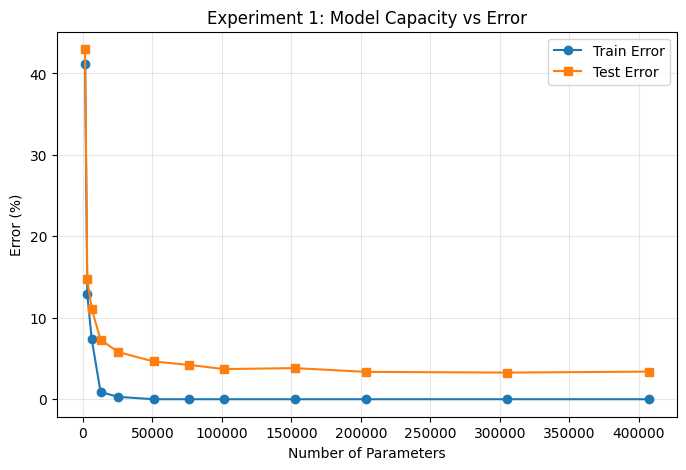

In [ ]:
widths = [2, 4, 8, 16, 32, 64, 96, 128, 192, 256, 384, 512]
n_params_list = []
train_errs_w, test_errs_w = [], []

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

for w in widths:
    model = Net(w)
    n_params = count_params(model)
    n_params_list.append(n_params)

    tr_err, te_err = train_and_eval(model, train_loader, test_loader, epochs=40, lr=0.001)
    train_errs_w.append(tr_err)
    test_errs_w.append(te_err)

    print(f"Width {w:3d} | Params: {n_params:6d} | Train Error: {tr_err:6.2f}% | Test Error: {te_err:6.2f}%")

plt.figure(figsize=(8, 5))
plt.plot(n_params_list, train_errs_w, marker='o', label='Train Error')
plt.plot(n_params_list, test_errs_w, marker='s', label='Test Error')
plt.title("Experiment 1: Model Capacity vs Error")
plt.xlabel("Number of Parameters")
plt.ylabel("Error (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The  behavior is consistent with a transition between the under and over-parameterized regime, with no pbservation of the  double-descent curve

For very small widths (2–4), the model is clearly underfitting: the training and test error is high.  Increasing the width to intermediate values (​16–64) rapidly improves both  training and test errors. Here, the model acquires enough capacity to fit the data

Around width 64, the model is the interpolation regime: the training error drops to 0%. This is the critical point where a peak in the test error would be expected (the double-descent). but nothing is observed: the test error is already low (4.6%) and continues to improve  by increasing the width (up to 3.27%) converging around this last value augmentig the size

this is why I think I don't observe double descent: the dataset is too "easy", so there is no significant noise in the labels. and double descent should emerge more clearly when the model is forced to interpolate noise or tricky patterns in the data whichs should mislead the models. If the labels are perfectly clean, interpolating does not heavily penalize final test accuracy because there is no noise at all that could mislead the model

Now I ll try with the other architecture

Width   2 | Params:   1606 | Train Error:  72.29% | Test Error:  73.21%
Width   4 | Params:   3210 | Train Error:  12.84% | Test Error:  14.64%
Width   8 | Params:   6442 | Train Error:   4.33% | Test Error:   9.08%
Width  16 | Params:  13002 | Train Error:   0.97% | Test Error:   6.96%
Width  32 | Params:  26506 | Train Error:   2.46% | Test Error:   7.23%
Width  64 | Params:  55050 | Train Error:   0.00% | Test Error:   4.23%
Width  96 | Params:  85642 | Train Error:   0.00% | Test Error:   3.90%
Width 128 | Params: 118282 | Train Error:   0.00% | Test Error:   3.35%
Width 192 | Params: 189706 | Train Error:   0.00% | Test Error:   3.24%
Width 256 | Params: 269322 | Train Error:   0.00% | Test Error:   3.21%


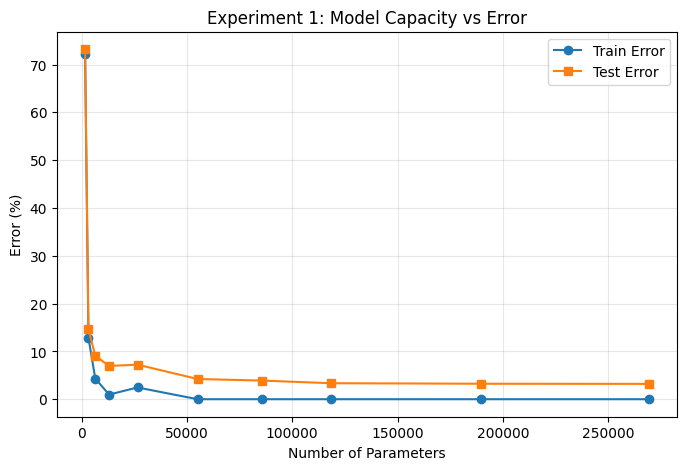

In [ ]:
widths = [2, 4, 8, 16, 32, 64, 96, 128, 192, 256]
n_params_list = []
train_errs_w, test_errs_w = [], []

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

for w in widths:
    model = Net_2(w)
    n_params = count_params(model)
    n_params_list.append(n_params)

    tr_err, te_err = train_and_eval(model, train_loader, test_loader, epochs=40, lr=0.001)
    train_errs_w.append(tr_err)
    test_errs_w.append(te_err)

    print(f"Width {w:3d} | Params: {n_params:6d} | Train Error: {tr_err:6.2f}% | Test Error: {te_err:6.2f}%")

plt.figure(figsize=(8, 5))
plt.plot(n_params_list, train_errs_w, marker='o', label='Train Error')
plt.plot(n_params_list, test_errs_w, marker='s', label='Test Error')
plt.title("Experiment 1: Model Capacity vs Error")
plt.xlabel("Number of Parameters")
plt.ylabel("Error (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

We are in the same identical situation as before so I can get the same conclusions as before, except for this little detail:
- There is a spike before the interpolation (width 32: the train error increases and the test error worsens). I don t know why.

too see double descent maybe I need to sample much more densely the area around the point where the training error becomes exactly zero, because that's where the test error peak should appear.
So it makes sense to" zoom in "locally, around 64, which is my observed interpolation threshold, for example, by trying many values ​​between about 32 and 80.
Since even 2% train error at width 32 is a low percentage and there are many models between widths 32 and 64, I'll start by seeing if interpolation is reached before "64-width", and  how much, before training heavier models and searching in vain

Width   2 | Params:   1606 | Train Error:  64.09% | Test Error:  64.66%
Width   4 | Params:   3210 | Train Error:  27.40% | Test Error:  29.27%
Width   8 | Params:   6442 | Train Error:   5.12% | Test Error:   9.80%
Width  16 | Params:  13002 | Train Error:   0.45% | Test Error:   6.91%
Width  18 | Params:  14662 | Train Error:   0.82% | Test Error:   7.07%
Width  20 | Params:  16330 | Train Error:   1.01% | Test Error:   7.26%
Width  22 | Params:  18006 | Train Error:   0.08% | Test Error:   6.32%
Width  24 | Params:  19690 | Train Error:   0.23% | Test Error:   6.25%
Width  26 | Params:  21382 | Train Error:   0.00% | Test Error:   5.46%
Width  28 | Params:  23082 | Train Error:   1.02% | Test Error:   6.66%
Width  30 | Params:  24790 | Train Error:   0.00% | Test Error:   5.44%
Width  32 | Params:  26506 | Train Error:   0.00% | Test Error:   5.29%
Width  35 | Params:  29095 | Train Error:   0.00% | Test Error:   4.96%


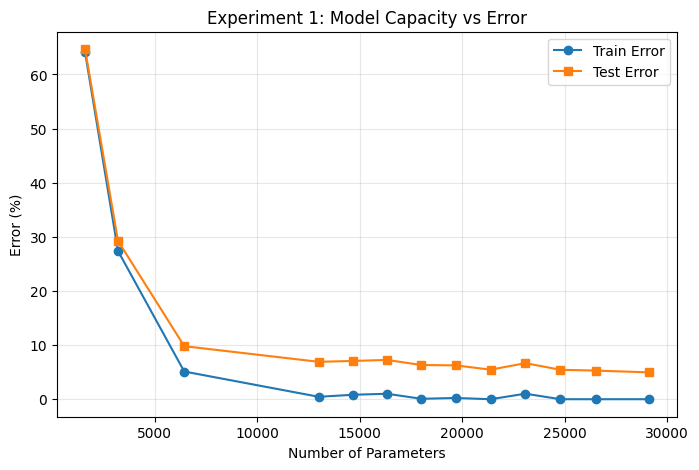

In [ ]:
widths = [2, 4, 8, 16,18,20,22,24,26,28,30, 32, 35]
n_params_list = []
train_errs_w, test_errs_w = [], []

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

for w in widths:
    model = Net_2(w)
    n_params = count_params(model)
    n_params_list.append(n_params)

    tr_err, te_err = train_and_eval(model, train_loader, test_loader, epochs=40, lr=0.001)
    train_errs_w.append(tr_err)
    test_errs_w.append(te_err)

    print(f"Width {w:3d} | Params: {n_params:6d} | Train Error: {tr_err:6.2f}% | Test Error: {te_err:6.2f}%")

plt.figure(figsize=(8, 5))
plt.plot(n_params_list, train_errs_w, marker='o', label='Train Error')
plt.plot(n_params_list, test_errs_w, marker='s', label='Test Error')
plt.title("Experiment 1: Model Capacity vs Error")
plt.xlabel("Number of Parameters")
plt.ylabel("Error (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The transition to interpolation is not a clear transition: the train error oscillates around 0
The test error shows small  oscillations too

No high test error peak appears at the interpolation point. It's not clear where exactly it is. The candidates:
- Width 26 | Params: 21382 | Train Error: 0.00% | Test Error: 5.46% ?
- Width 30 | Params: 24790 | Train Error: 0.00% | Test Error: 5.44%  ?
- Width 32 | Params: 26506 | Train Error: 0.00% | Test Error: 5.29% ?

 double descent is not observed probably because the interpolation region is unstable (there is no sharp critical transition) and there are test error variations around them
 
in the next experiment I ll try again but focusing more around width 30 and bigger models since the real interpolation should be in that area, there is no need to explore after the 64-width since we are already or very near in the interpolation point

Width  29 | Params:  23935 | Train Error:   0.15% | Test Error:   5.84%
Width  30 | Params:  24790 | Train Error:   0.00% | Test Error:   5.33%
Width  31 | Params:  25647 | Train Error:   0.00% | Test Error:   5.11%
Width  32 | Params:  26506 | Train Error:   0.01% | Test Error:   5.14%
Width  33 | Params:  27367 | Train Error:   2.28% | Test Error:   7.38%
Width  34 | Params:  28230 | Train Error:   0.00% | Test Error:   5.15%
Width  35 | Params:  29095 | Train Error:   0.00% | Test Error:   5.01%
Width  36 | Params:  29962 | Train Error:   0.00% | Test Error:   5.28%
Width  37 | Params:  30831 | Train Error:   0.00% | Test Error:   4.92%
Width  38 | Params:  31702 | Train Error:   0.00% | Test Error:   5.19%
Width  39 | Params:  32575 | Train Error:   0.00% | Test Error:   4.80%
Width  40 | Params:  33450 | Train Error:   0.00% | Test Error:   4.80%


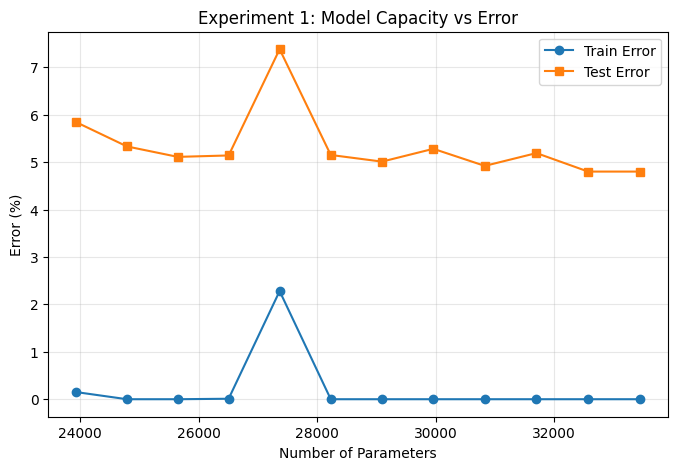

In [4]:
widths =  list(range(29, 41, 1)) #from 29 to 40 every 1
n_params_list = []
train_errs_w, test_errs_w = [], []

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

for w in widths:
    model = Net_2(w)
    n_params = count_params(model)
    n_params_list.append(n_params)

    tr_err, te_err = train_and_eval(model, train_loader, test_loader, epochs=40, lr=0.001)
    train_errs_w.append(tr_err)
    test_errs_w.append(te_err)

    print(f"Width {w:3d} | Params: {n_params:6d} | Train Error: {tr_err:6.2f}% | Test Error: {te_err:6.2f}%")

plt.figure(figsize=(8, 5))
plt.plot(n_params_list, train_errs_w, marker='o', label='Train Error')
plt.plot(n_params_list, test_errs_w, marker='s', label='Test Error')
plt.title("Experiment 1: Model Capacity vs Error")
plt.xlabel("Number of Parameters")
plt.ylabel("Error (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The transition to interpolation occurs around width 30, but it is not  stable, since a anomaly appears at width 33

The test error shows noticeable local oscillations throughout the post-interpolation region, with small ups and downs at widths 32, 34, 36, and 38, and one pronounced spike at width 33.

Conclusion: no clear double descent is observed, because there is no peak exactly associated with the interpolation threshold, followed by a consistent second descent. Instead, the overall behaviour is a generally improving  with some fluctuations

Experiment failed


### Experiment 2 training epochs

 Here I keep the architecture fixed and I change the number of epochs. double descent can also appear over time, not only when model size changes

I choose a "large" (the 256-width one) model, because a small model may not be expressive enough. A wider network should have a better chance to fit the training data quite well and being for sure in a overparametrized regime. ( and so observing the double desc. from a few epochs acrossing the interpolation threshold and then finishing in the over parametrized regime, if model is not sufficient complex I can t see the full transition for sure)

So I evaluate the model at different epochs. In this experiment, the loss is also useful because it gives more detailed information than the error rate. Error only says if the prediction is right or wrong, while loss  shows how confident the model is about that specific prediction




epoch = 1 , train Loss = 0.24505990347862244 , train Error = 7.369999999999999 , test Loss = 0.28338107615709307 , test Error = 8.550000000000002
epoch = 2 , train Loss = 0.15480279042720796 , train Error = 4.520000000000001 , test Loss = 0.20912551283836364 , test Error = 6.169999999999998
epoch = 3 , train Loss = 0.09227323613166809 , train Error = 2.529999999999999 , test Loss = 0.16844199523329734 , test Error = 4.9399999999999995
epoch = 4 , train Loss = 0.0660101215660572 , train Error = 1.8399999999999972 , test Loss = 0.15721693634986877 , test Error = 4.700000000000005
epoch = 5 , train Loss = 0.046597845715284344 , train Error = 1.1399999999999966 , test Loss = 0.14331772215664387 , test Error = 4.239999999999999
epoch = 6 , train Loss = 0.03260640980899334 , train Error = 0.5099999999999993 , test Loss = 0.1389351338148117 , test Error = 4.190000000000005
epoch = 7 , train Loss = 0.032503762821108104 , train Error = 0.7299999999999973 , test Loss = 0.15240126438438892 , test

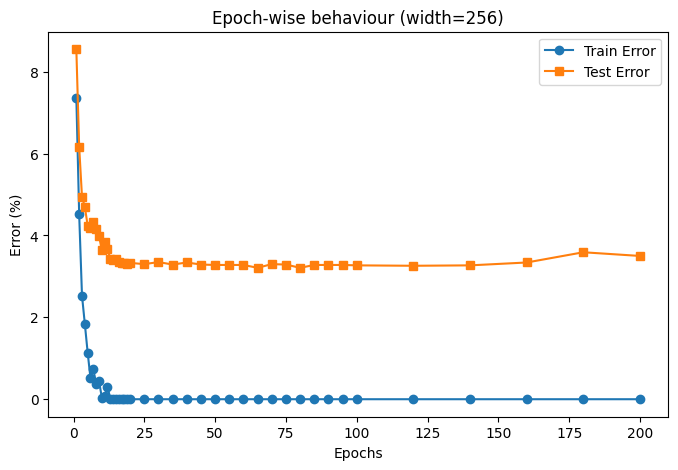

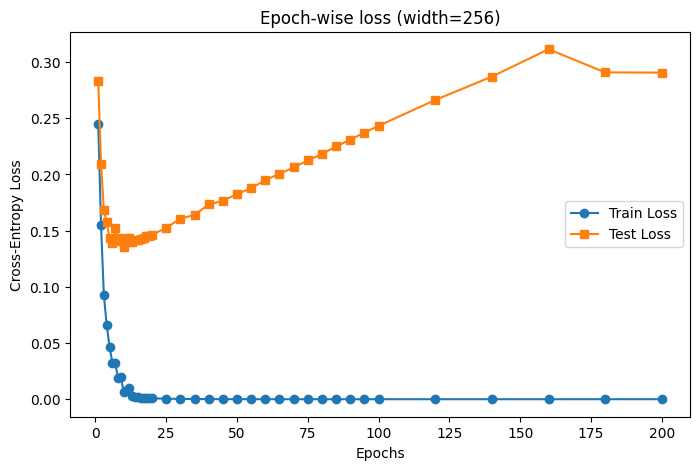

In [ ]:
epoch_schedule = list(range(1, 21)) + list(range(25, 101, 5)) + list(range(120, 201, 20))
#Epochs 1-20 (Every 1): Maximum control. Initially, the model learns quickly and changes are drastic.
#Epochs 25-100 (Every 5): Moderate control
#Epochs 120-200 (Every 20): Minimum control


train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)



model_ep = Net(256).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_ep.parameters(), lr=0.001)


epochs_saved = []
train_losses = []
train_errs = []
test_losses = []
test_errs = []





for ep in range(1, 201):
    model_ep.train()

    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()
        out = model_ep(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

    if ep in epoch_schedule:
        train_loss, train_err = evaluate(model_ep, train_loader, criterion)
        test_loss, test_err = evaluate(model_ep, test_loader, criterion)

        epochs_saved.append(ep)
        train_losses.append(train_loss)
        train_errs.append(train_err)
        test_losses.append(test_loss)
        test_errs.append(test_err)

        print("epoch =", ep,", train Loss =", train_loss,", train Error =", train_err,", test Loss =", test_loss,", test Error =", test_err)

# plot errors
plt.figure(figsize=(8, 5))
plt.plot(epochs_saved, train_errs, marker='o', label='Train Error')
plt.plot(epochs_saved, test_errs, marker='s', label='Test Error')
plt.title("Epoch-wise behaviour (width=256)")
plt.xlabel("Epochs")
plt.ylabel("Error (%)")
plt.legend()
plt.show()

# plot losses
plt.figure(figsize=(8, 5))
plt.plot(epochs_saved, train_losses, marker='o', label='Train Loss')
plt.plot(epochs_saved, test_losses, marker='s', label='Test Loss')
plt.title("Epoch-wise loss (width=256)")
plt.xlabel("Epochs")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.show()

The train error reaches 0% very early (epoch 14) and remains stable

The test error decreases initially (epochs 10–15), then stabilizes

The test loss increases( it doubles in the end) after interpolation, but this is not reflected in an increase in the error rate.This is really strange
There is no sharp peak in the test error immediately after the interpolation point.

Conclusion:
No double descent is observed over time. I don ' t know why

### Experiment 3 Dataset size

In this experiment, I change the number of training samples. 
In fact, the interpolation regime does not depend only on the model, but also on how many training examples the model sees. A model can be small for one dataset size and large for another

The dataset sizes go from very small to larger subsets. With few samples, learning is harder. With more samples, the model can generalize better.

if it s true that : parameters = dataset * 10 to get the threshold (just euristics choice) ,I will choose width=24 (about 20k parameters) so that the critical region may fall near 2000 samples. This makes it easier to observe changes in performance when the dataset size increases

Anyway for completeness of the experiment and since this is also a very euristics choice, I will try also other width slighter larger and smaller than 24




In [5]:
w = 24
par = count_params(Net_2(w))
print(f"Parameters of model with width {w}: {par:,}")

Parameters of model with width 24: 19,690


MODEL WITH WIDTH:   18.00
N=  100 | Train Error:   4.00% | Test Error:  41.34%
N=  200 | Train Error:   1.50% | Test Error:  23.68%
N=  500 | Train Error:   0.60% | Test Error:  18.51%
N= 1000 | Train Error:   0.00% | Test Error:  11.74%
N= 2000 | Train Error:   0.00% | Test Error:  10.00%
N= 3000 | Train Error:   0.03% | Test Error:   9.36%
N= 5000 | Train Error:   0.26% | Test Error:   8.80%
N= 7500 | Train Error:   0.59% | Test Error:   7.64%
N=10000 | Train Error:   0.31% | Test Error:   6.80%


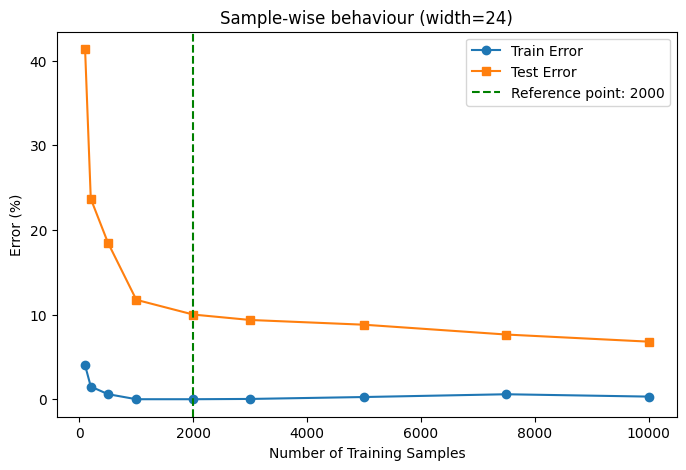

MODEL WITH WIDTH:   20.00
N=  100 | Train Error:   1.00% | Test Error:  29.62%
N=  200 | Train Error:   0.00% | Test Error:  26.16%
N=  500 | Train Error:   0.00% | Test Error:  14.11%
N= 1000 | Train Error:   0.40% | Test Error:  13.16%
N= 2000 | Train Error:   0.05% | Test Error:  10.59%
N= 3000 | Train Error:   0.27% | Test Error:  10.48%
N= 5000 | Train Error:   0.04% | Test Error:   7.77%
N= 7500 | Train Error:   0.25% | Test Error:   7.77%
N=10000 | Train Error:   0.13% | Test Error:   6.54%


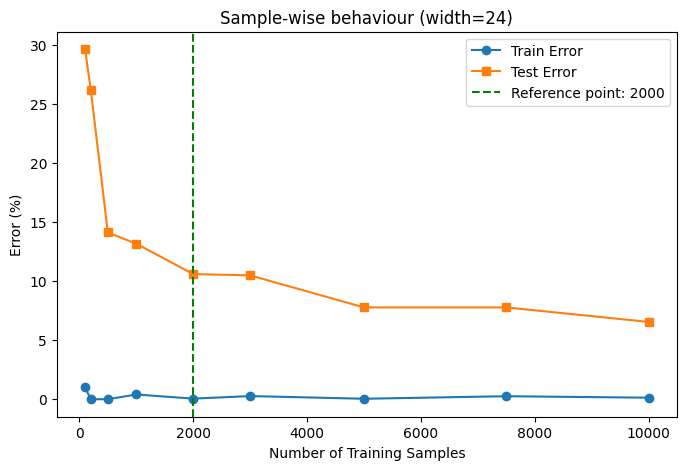

MODEL WITH WIDTH:   22.00
N=  100 | Train Error:   3.00% | Test Error:  33.88%
N=  200 | Train Error:   0.00% | Test Error:  20.95%
N=  500 | Train Error:   0.20% | Test Error:  14.86%
N= 1000 | Train Error:   0.10% | Test Error:  12.12%
N= 2000 | Train Error:   0.00% | Test Error:  10.04%
N= 3000 | Train Error:   0.00% | Test Error:   8.83%
N= 5000 | Train Error:   0.04% | Test Error:   7.82%
N= 7500 | Train Error:   0.01% | Test Error:   7.05%
N=10000 | Train Error:   0.18% | Test Error:   6.08%


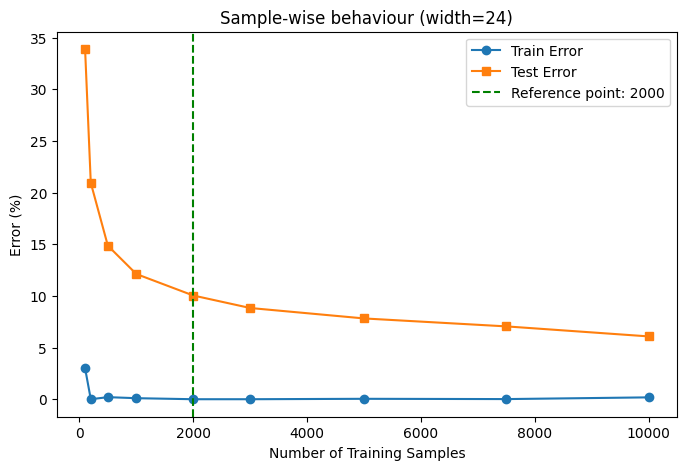

MODEL WITH WIDTH:   24.00
N=  100 | Train Error:   1.00% | Test Error:  31.93%
N=  200 | Train Error:   1.00% | Test Error:  20.11%
N=  500 | Train Error:   0.00% | Test Error:  13.51%
N= 1000 | Train Error:   0.00% | Test Error:  11.58%
N= 2000 | Train Error:   0.10% | Test Error:   9.80%
N= 3000 | Train Error:   0.00% | Test Error:   9.42%
N= 5000 | Train Error:   0.12% | Test Error:   7.88%
N= 7500 | Train Error:   0.04% | Test Error:   6.96%
N=10000 | Train Error:   0.00% | Test Error:   6.06%


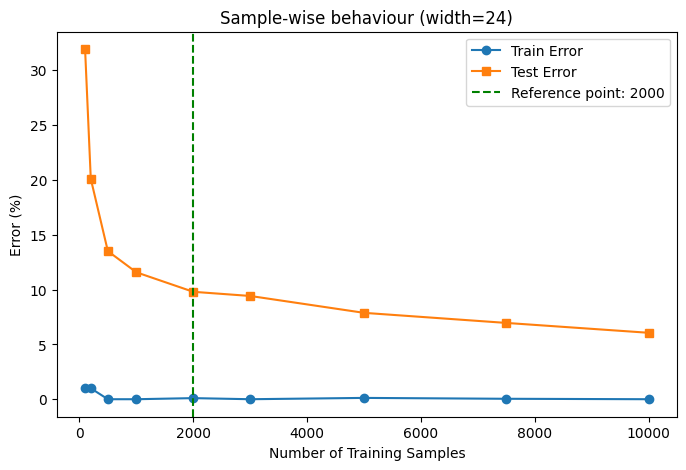

MODEL WITH WIDTH:   26.00
N=  100 | Train Error:   0.00% | Test Error:  29.35%
N=  200 | Train Error:   0.00% | Test Error:  21.56%
N=  500 | Train Error:   0.00% | Test Error:  15.17%
N= 1000 | Train Error:   0.00% | Test Error:  12.43%
N= 2000 | Train Error:   0.00% | Test Error:  10.05%
N= 3000 | Train Error:   0.00% | Test Error:   9.13%
N= 5000 | Train Error:   0.00% | Test Error:   7.77%
N= 7500 | Train Error:   0.04% | Test Error:   6.62%
N=10000 | Train Error:   0.13% | Test Error:   6.35%


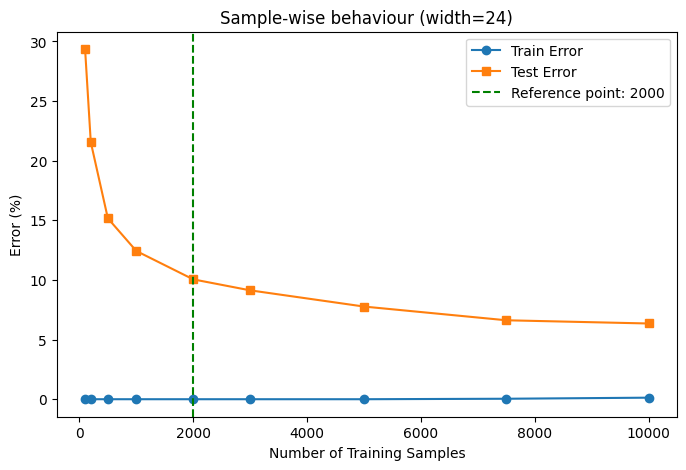

MODEL WITH WIDTH:   28.00
N=  100 | Train Error:   0.00% | Test Error:  31.88%
N=  200 | Train Error:   0.00% | Test Error:  19.74%
N=  500 | Train Error:   0.00% | Test Error:  14.75%
N= 1000 | Train Error:   0.00% | Test Error:  11.69%
N= 2000 | Train Error:   0.00% | Test Error:   9.77%
N= 3000 | Train Error:   0.00% | Test Error:   8.77%
N= 5000 | Train Error:   0.00% | Test Error:   6.70%
N= 7500 | Train Error:   0.00% | Test Error:   6.62%
N=10000 | Train Error:   0.02% | Test Error:   6.34%


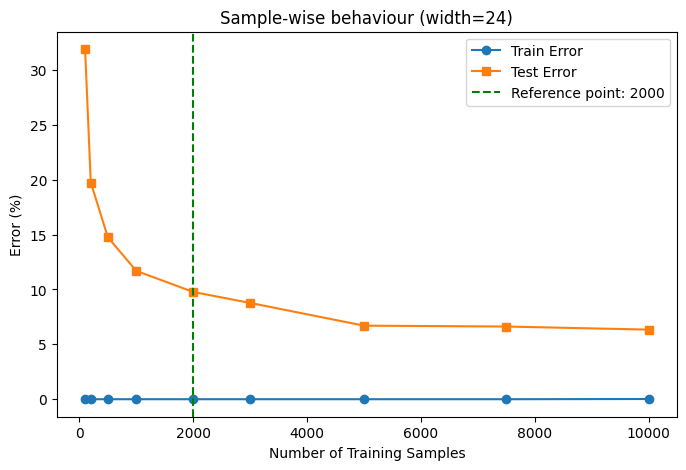

In [ ]:
data_sizes = [100, 200, 500, 1000, 2000, 3000, 5000, 7500, 10000]
widths = [18,20,22,24,26,28]

for w in widths:
  print(f"MODEL WITH WIDTH:  {w:6.2f}")

  data_tr_errs = []
  data_te_errs = []

  for n in data_sizes:
      idx = torch.randperm(len(full_train))[:n]
      subset_n = Subset(full_train, idx)
      train_loader_n = DataLoader(subset_n, batch_size=64, shuffle=True)

      model_n = Net_2(w)   # heuristic choice: critical region may be near 2000 samples
      tr_err, te_err = train_and_eval(model_n, train_loader_n, test_loader, epochs=40)

      data_tr_errs.append(tr_err)
      data_te_errs.append(te_err)

      print(f"N={n:5d} | Train Error: {tr_err:6.2f}% | Test Error: {te_err:6.2f}%")

  plt.figure(figsize=(8, 5))
  plt.plot(data_sizes, data_tr_errs, marker='o', label='Train Error')
  plt.plot(data_sizes, data_te_errs, marker='s', label='Test Error')
  plt.title("Sample-wise behaviour (width=24)")
  plt.xlabel("Number of Training Samples")
  plt.ylabel("Error (%)")
  plt.axvline(2000, color='green', linestyle='--', label='Reference point: 2000')
  plt.legend()
  plt.show()

# Conclusion for all cases of experiment 3

As the number of samples increases, the test error decreases  monotonically for all the cases.
The train error also remains low, 0% or near, even with few samples. This means that models have sufficient capacity to interpolate almost the entire training set across the entire range considered, and the increase in data mainly improves generalization.
Consequently, increasing the samples simply achieves the standard effect: more data  improves generalization. This produces a monotonically decreasing curve, not the shape of double descent. 

This is true for all widths so this is not related to the single architecture itsself. there should be a reason that is in common with all these models and explains why it happens. I don t know which one could be


